# IDX Exchange DA Internship - Week Seven - Outlier Detection and Data Quality

* Submit a .py script applying IQR filtering to key numeric fields (ClosePrice, LivingArea, DaysOnMarket).
* Add outlier flag columns rather than deleting records outright.
* Save both a full flagged dataset and a clean filtered dataset.
* Include a written comparison of dataset size and median values before and after filtering.

--------

In [241]:
import pandas as pd
import matplotlib.pyplot as plt

In order for our analysis to go forward, we must remove outliers from our dataset. This is important because outliers can massively skew the market metrics calculated from our data. Since most of the data has a right skew, we can expect to remove more large values than small ones, but outliers in both directions must be handled. This notebook will first flag rows that contain outliers according to the IQR rule. Then, a more thorough check of outliers will be done using percentiles and histograms. Once the distribution of that particular feature has been grasped, a unique outlier removal strategy for that feature will be implemented. Thus, by the end of this notebook, we will create an outliers-flagged and an outliers-dropped version of each dataset.

## Import Datasets

In [242]:
# Import the listings and sold datasets from week six

listings = pd.read_csv("listings_week_6.csv", low_memory=False)
sold = pd.read_csv("sold_week_6.csv", low_memory=False)

## Outlier Handling

Outliers will be flagged according to the IQR rule. Then, to avoid naively dropping many rows, we will invesitgate the distribution of each feature to create appropirate cutoffs for outlier dropping.

In [243]:
# Write a function that will flag outliers, given a feature and its dataset

def flagging(dataset, col):
    Q1 = dataset[col].quantile(0.25)
    Q3 = dataset[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    print(lower)
    print(upper)
    return ((dataset[col] >= lower) & (dataset[col] <= upper)) | (dataset[col].isnull() == True)

In [244]:
# Make two versions of the original datasets, one where outliers will be flagged and one where they'll be dropped

listings_flag = listings.copy()
listings_drop = listings.copy()

sold_flag = sold.copy()
sold_drop = sold.copy()

### ClosePrice

In [245]:
# Flag outliers of ClosePrice according to the IQR rule

listings_flag["ClosePrice_outflag"] = flagging(listings_flag, "ClosePrice")
print(listings_flag["ClosePrice_outflag"].value_counts())

print("-------")

sold_flag["ClosePrice_outflag"] = flagging(sold_flag, "ClosePrice")
print(sold_flag["ClosePrice_outflag"].value_counts())

-525000.0
2475000.0
ClosePrice_outflag
True     533850
False      9868
Name: count, dtype: int64
-------
-512500.0
2387500.0
ClosePrice_outflag
True     381023
False     30606
Name: count, dtype: int64


In [246]:
# For actually dropping outliers, do this more thoughtfully

print(listings_flag["ClosePrice"].quantile(0.03))
print(listings_flag["ClosePrice"].quantile(0.97))

print("------")

print(sold_flag["ClosePrice"].quantile(0.03))
print(sold_flag["ClosePrice"].quantile(0.97))

303000.0
3607751.4999999753
------
290000.0
3565000.0


Text(0, 0.5, 'Count of Properties')

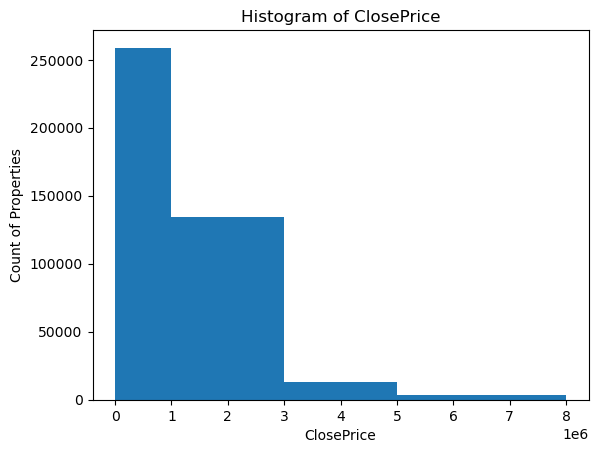

In [247]:
plt.hist(sold_flag["ClosePrice"], bins=[0, 1000000, 3000000, 5000000, 8000000])
plt.title("Histogram of ClosePrice")
plt.xlabel("ClosePrice")
plt.ylabel("Count of Properties")

In [248]:
# Sales below $10,000 are very unlikely, we'll make that the lower cutoff
listings_drop = listings_drop[~(listings_drop["ClosePrice"] <= 10000)]
sold_drop = sold_drop[~(sold_drop["ClosePrice"] <= 10000)]

# Sales higher than the 3,000,000 are very unlikely, we'll make that the higher cutoff
listings_drop = listings_drop[~(listings_drop["ClosePrice"] >= 3000000)]
sold_drop = sold_drop[~(sold_drop["ClosePrice"] >= 3000000)]

### OriginalListPrice

In [249]:
# Flag outliers of OriginalListPrice according to the IQR rule

listings_flag["OriginalListPrice_outflag"] = flagging(listings_flag, "OriginalListPrice")
print(listings_flag["OriginalListPrice_outflag"].value_counts())

print("-------")

sold_flag["OriginalListPrice_outflag"] = flagging(sold_flag, "OriginalListPrice")
print(sold_flag["OriginalListPrice_outflag"].value_counts())

-625307.5
2607184.5
OriginalListPrice_outflag
True     498745
False     44973
Name: count, dtype: int64
-------
-486000.0
2370000.0
OriginalListPrice_outflag
True     379304
False     32325
Name: count, dtype: int64


In [250]:
# For actually dropping outliers, do this more thoughtfully

print(listings_flag["OriginalListPrice"].quantile(0.03))
print(listings_flag["OriginalListPrice"].quantile(0.97))

print("------")

print(sold_flag["OriginalListPrice"].quantile(0.03))
print(sold_flag["OriginalListPrice"].quantile(0.97))

299000.0
4500000.0
------
299900.0
3695000.0


Text(0, 0.5, 'Count of Properties')

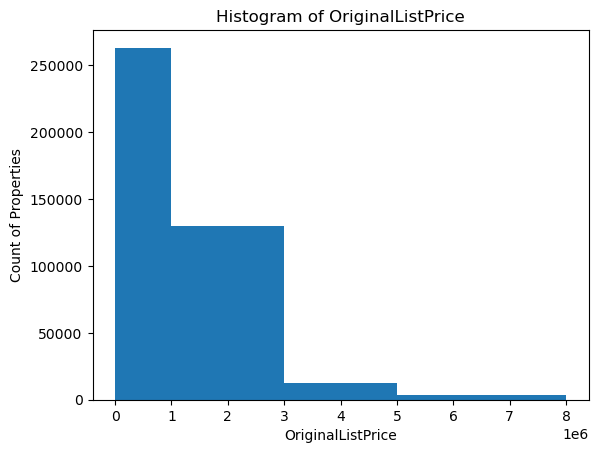

In [251]:
plt.hist(sold_flag["OriginalListPrice"], bins=[0, 1000000, 3000000, 5000000, 8000000])
plt.title("Histogram of OriginalListPrice")
plt.xlabel("OriginalListPrice")
plt.ylabel("Count of Properties")

In [252]:
# Sales below $10,000 are very unlikely, we'll make that the lower cutoff
listings_drop = listings_drop[~(listings_drop["OriginalListPrice"] <= 10000)]
sold_drop = sold_drop[~(sold_drop["OriginalListPrice"] <= 10000)]

# Sales higher than the 4,000,000 are very unlikely, we'll make that the higher cutoff
# Note that the cutoff for ClosePrice was 3,000,000. We can allow for a higher OriginalListPrice because we expect it to drop later
listings_drop = listings_drop[~(listings_drop["OriginalListPrice"] >= 4000000)]
sold_drop = sold_drop[~(sold_drop["OriginalListPrice"] >= 4000000)]

### ListPrice

In [253]:
# Flag outliers of ListPrice according to the IQR rule

listings_flag["ListPrice_outflag"] = flagging(listings_flag, "ListPrice")
print(listings_flag["ListPrice_outflag"].value_counts())

print("-------")

sold_flag["ListPrice_outflag"] = flagging(sold_flag, "ListPrice")
print(sold_flag["ListPrice_outflag"].value_counts())

-620000.0
2588000.0
ListPrice_outflag
True     498126
False     45592
Name: count, dtype: int64
-------
-505000.0
2375000.0
ListPrice_outflag
True     380851
False     30778
Name: count, dtype: int64


In [254]:
# For actually dropping outliers, do this more thoughtfully

print(listings_flag["ListPrice"].quantile(0.03))
print(listings_flag["ListPrice"].quantile(0.97))

print("------")

print(sold_flag["ListPrice"].quantile(0.03))
print(sold_flag["ListPrice"].quantile(0.97))

299000.0
4495000.0
------
299000.0
3588000.0


Text(0, 0.5, 'Count of Properties')

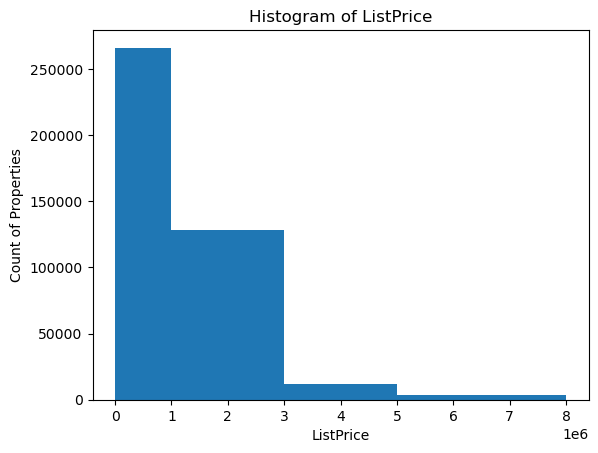

In [255]:
plt.hist(sold_flag["ListPrice"], bins=[0, 1000000, 3000000, 5000000, 8000000])
plt.title("Histogram of ListPrice")
plt.xlabel("ListPrice")
plt.ylabel("Count of Properties")

In [256]:
# Sales below $10,000 are very unlikely, we'll make that the lower cutoff
listings_drop = listings_drop[~(listings_drop["ListPrice"] <= 10000)]
sold_drop = sold_drop[~(sold_drop["ListPrice"] <= 10000)]

# Sales higher than the 4,000,000 are very unlikely, we'll make that the higher cutoff
# Note that the cutoff for ClosePrice was 3,000,000. We can allow for a higher ListPrice because we expect it to drop later
listings_drop = listings_drop[~(listings_drop["ListPrice"] >= 4000000)]
sold_drop = sold_drop[~(sold_drop["ListPrice"] >= 4000000)]

### OriginPriceRatio

In [257]:
# Flag outliers of OriginPriceRatio according to the IQR rule

listings_flag["OriginPriceRatio_outflag"] = flagging(listings_flag, "OriginPriceRatio")
print(listings_flag["OriginPriceRatio_outflag"].value_counts())

print("-------")

sold_flag["OriginPriceRatio_outflag"] = flagging(sold_flag, "OriginPriceRatio")
print(sold_flag["OriginPriceRatio_outflag"].value_counts())

0.8768406130793651
1.1167527750095236
OriginPriceRatio_outflag
True     529640
False     14078
Name: count, dtype: int64
-------
0.8553389227371655
1.117691330564178
OriginPriceRatio_outflag
True     372550
False     39079
Name: count, dtype: int64


In [258]:
# For actually dropping outliers, do this more thoughtfully

print(listings_flag["OriginPriceRatio"].quantile(0.03))
print(listings_flag["OriginPriceRatio"].quantile(0.97))

print("------")

print(sold_flag["OriginPriceRatio"].quantile(0.03))
print(sold_flag["OriginPriceRatio"].quantile(0.97))

0.8623773682539329
1.1859011837828164
------
0.8260869565217391
1.1578947368421053


Text(0, 0.5, 'Count of Properties')

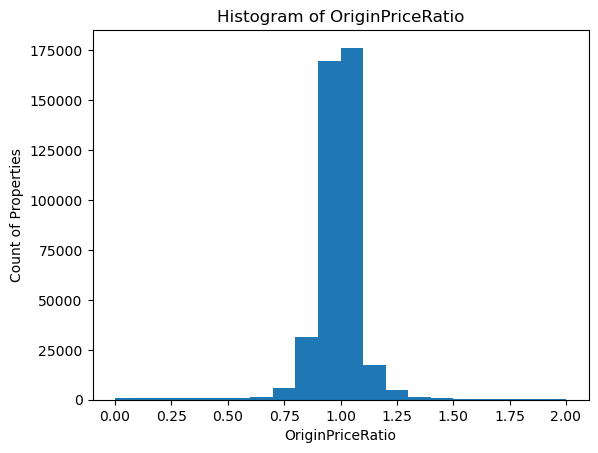

In [259]:
plt.hist(sold_flag["OriginPriceRatio"], bins=[0, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 2])
plt.title("Histogram of OriginPriceRatio")
plt.xlabel("OriginPriceRatio")
plt.ylabel("Count of Properties")

In [260]:
# OriginPriceRatio below 0.7 are very unlikely, we'll make that the lower cutoff
listings_drop = listings_drop[~(listings_drop["OriginPriceRatio"] <= 0.7)]
sold_drop = sold_drop[~(sold_drop["OriginPriceRatio"] <= 0.7)]

# OriginPriceRatio higher than the 1.3 are very unlikely, we'll make that the higher cutoff
listings_drop = listings_drop[~(listings_drop["OriginPriceRatio"] >= 1.3)]
sold_drop = sold_drop[~(sold_drop["OriginPriceRatio"] >= 1.3)]

### PriceRatio

In [261]:
# Flag outliers of PriceRatio according to the IQR rule

listings_flag["PriceRatio_outflag"] = flagging(listings_flag, "PriceRatio")
print(listings_flag["PriceRatio_outflag"].value_counts())

print("-------")

sold_flag["PriceRatio_outflag"] = flagging(sold_flag, "PriceRatio")
print(sold_flag["PriceRatio_outflag"].value_counts())

0.9135640478924061
1.0928872122901971
PriceRatio_outflag
True     528046
False     15672
Name: count, dtype: int64
-------
0.9116117714100714
1.0843215883322959
PriceRatio_outflag
True     365683
False     45946
Name: count, dtype: int64


In [262]:
# For actually dropping outliers, do this more thoughtfully

print(listings_flag["PriceRatio"].quantile(0.03))
print(listings_flag["PriceRatio"].quantile(0.97))

print("------")

print(sold_flag["PriceRatio"].quantile(0.03))
print(sold_flag["PriceRatio"].quantile(0.97))

0.9091735612328392
1.176941553242594
------
0.8993319945353151
1.1487179487179486


Text(0, 0.5, 'Count of Properties')

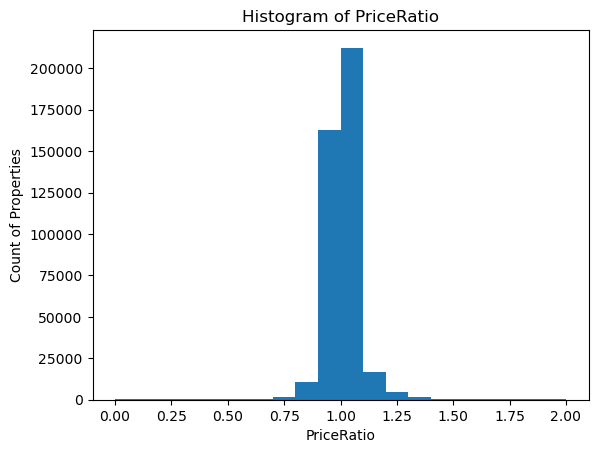

In [263]:
plt.hist(sold_flag["PriceRatio"], bins=[0, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 2])
plt.title("Histogram of PriceRatio")
plt.xlabel("PriceRatio")
plt.ylabel("Count of Properties")

In [264]:
# PriceRatio below 0.7 are very unlikely, we'll make that the lower cutoff
listings_drop = listings_drop[~(listings_drop["PriceRatio"] <= 0.7)]
sold_drop = sold_drop[~(sold_drop["PriceRatio"] <= 0.7)]

# PriceRatio higher than the 1.3 are very unlikely, we'll make that the higher cutoff
listings_drop = listings_drop[~(listings_drop["PriceRatio"] >= 1.3)]
sold_drop = sold_drop[~(sold_drop["PriceRatio"] >= 1.3)]

### LivingArea

In [265]:
# Flag outliers of LivingArea according to the IQR rule

listings_flag["LivingArea_outflag"] = flagging(listings_flag, "LivingArea")
print(listings_flag["LivingArea_outflag"].value_counts())

print("-------")

sold_flag["LivingArea_outflag"] = flagging(sold_flag, "LivingArea")
print(sold_flag["LivingArea_outflag"].value_counts())

-330.0
3878.0
LivingArea_outflag
True     516807
False     26911
Name: count, dtype: int64
-------
-208.5
3675.5
LivingArea_outflag
True     393494
False     18135
Name: count, dtype: int64


In [266]:
# For actually dropping outliers, do this more thoughtfully

print(listings_flag["LivingArea"].quantile(0.03))
print(listings_flag["LivingArea"].quantile(0.97))

print("------")

print(sold_flag["LivingArea"].quantile(0.03))
print(sold_flag["LivingArea"].quantile(0.97))

729.0
4488.0
------
752.0
4041.0


Text(0, 0.5, 'Count of Properties')

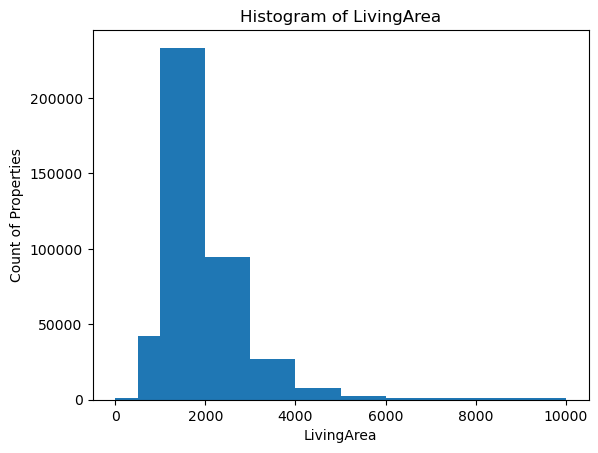

In [267]:
plt.hist(sold_flag["LivingArea"], bins=[0, 500, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 10000])
plt.title("Histogram of LivingArea")
plt.xlabel("LivingArea")
plt.ylabel("Count of Properties")

In [268]:
# LivingArea below 500 are very unlikely, we'll make that the lower cutoff
listings_drop = listings_drop[~(listings_drop["LivingArea"] <= 500)]
sold_drop = sold_drop[~(sold_drop["LivingArea"] <= 500)]

# LivingArea higher than the 5000 are very unlikely, we'll make that the higher cutoff
listings_drop = listings_drop[~(listings_drop["LivingArea"] >= 5000)]
sold_drop = sold_drop[~(sold_drop["LivingArea"] >= 5000)]

### PricePerSquareFoot

In [269]:
# Flag outliers of PricePerSquareFoot according to the IQR rule

listings_flag["PricePerSquareFoot_outflag"] = flagging(listings_flag, "PricePerSquareFoot")
print(listings_flag["PricePerSquareFoot_outflag"].value_counts())

print("-------")

sold_flag["PricePerSquareFoot_outflag"] = flagging(sold_flag, "PricePerSquareFoot")
print(sold_flag["PricePerSquareFoot_outflag"].value_counts())

-158.7588522182865
1314.8857535327174
PricePerSquareFoot_outflag
True     537431
False      6287
Name: count, dtype: int64
-------
-178.0721480404378
1278.8454591986524
PricePerSquareFoot_outflag
True     394111
False     17518
Name: count, dtype: int64


In [270]:
# For actually dropping outliers, do this more thoughtfully

print(listings_flag["PricePerSquareFoot"].quantile(0.03))
print(listings_flag["PricePerSquareFoot"].quantile(0.97))

print("------")

print(sold_flag["PricePerSquareFoot"].quantile(0.03))
print(sold_flag["PricePerSquareFoot"].quantile(0.97))

212.37532306108653
1495.4391744775155
------
203.6824490801577
1420.9132948487481


Text(0, 0.5, 'Count of Properties')

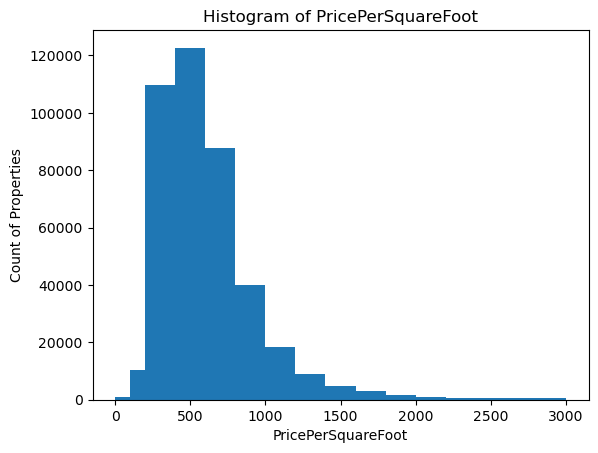

In [271]:
plt.hist(sold_flag["PricePerSquareFoot"], bins=[0, 100, 200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000, 2200, 2400, 2600, 3000])
plt.title("Histogram of PricePerSquareFoot")
plt.xlabel("PricePerSquareFoot")
plt.ylabel("Count of Properties")

In [272]:
# PricePerSquareFoot below 100 are very unlikely, we'll make that the lower cutoff
listings_drop = listings_drop[~(listings_drop["PricePerSquareFoot"] <= 100)]
sold_drop = sold_drop[~(sold_drop["PricePerSquareFoot"] <= 100)]

# PricePerSquareFoot higher than the 1600 are very unlikely, we'll make that the higher cutoff
listings_drop = listings_drop[~(listings_drop["PricePerSquareFoot"] >= 1600)]
sold_drop = sold_drop[~(sold_drop["PricePerSquareFoot"] >= 1600)]

### DaysOnMarket

In [273]:
# Flag outliers of DaysOnMarket according to the IQR rule

listings_flag["DaysOnMarket_outflag"] = flagging(listings_flag, "DaysOnMarket")
print(listings_flag["DaysOnMarket_outflag"].value_counts())

print("-------")

sold_flag["DaysOnMarket_outflag"] = flagging(sold_flag, "DaysOnMarket")
print(sold_flag["DaysOnMarket_outflag"].value_counts())

-19.0
45.0
DaysOnMarket_outflag
True     495274
False     48444
Name: count, dtype: int64
-------
-52.0
108.0
DaysOnMarket_outflag
True     379959
False     31670
Name: count, dtype: int64


In [274]:
# For actually dropping outliers, do this more thoughtfully

print(listings_flag["DaysOnMarket"].quantile(0.03))
print(listings_flag["DaysOnMarket"].quantile(0.97))

print("------")

print(sold_flag["DaysOnMarket"].quantile(0.03))
print(sold_flag["DaysOnMarket"].quantile(0.97))

0.0
93.0
------
0.0
161.0


Text(0, 0.5, 'Count of Properties')

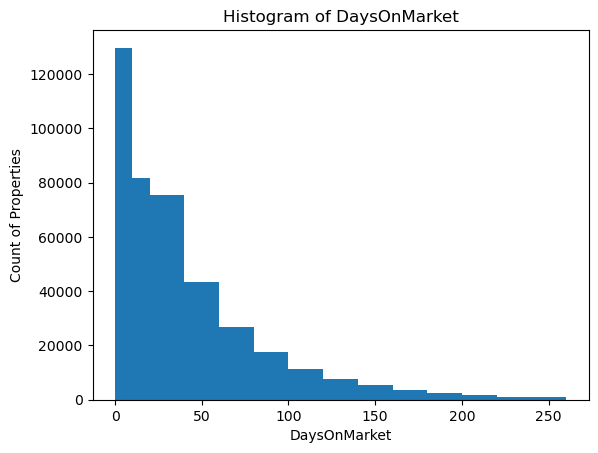

In [275]:
plt.hist(sold_flag["DaysOnMarket"], bins=[0, 10, 20, 40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260])
plt.title("Histogram of DaysOnMarket")
plt.xlabel("DaysOnMarket")
plt.ylabel("Count of Properties")

In [276]:
# No need to set a lower cutoff, it's already at 0

# DaysOnMarket has very different average values for the Listings and Sold datasets, handle them separately
# In the listings dataset, DaysOnMarket is unlikely to go above 100, make this the cutoff 
# In the sold dataset, DaysOnMarket is unlikely to go above 170, make this the cutoff 
listings_drop = listings_drop[~(listings_drop["DaysOnMarket"] >= 100)]
sold_drop = sold_drop[~(sold_drop["DaysOnMarket"] >= 170)]

## Summary

In [287]:
# Save the new flagged and filtered datasets

listings_flag.to_csv("listings_flag.csv", index=False)
listings_drop.to_csv("listings_drop.csv", index=False)
sold_flag.to_csv("sold_flag.csv", index=False)
sold_drop.to_csv("sold_drop.csv", index=False)

#### Dataset Rows Pre- and Post-Filtering

|  | Pre-Drop Rows | Post-Drop Rows | Total Rows Dropped | Percent Dropped |
| -- | ------------ | -------------- | ------------- | ------------ |
| Listings | 543,718 | 499,279 | 44,439 | 8.17% |
| Sold | 411,629 | 373,089 | 38,540 | 9.36% |

#### Median Values Pre- and Post-Filtering

| | ClosePrice | OriginalListPrice | ListPrice | OriginPriceRatio | PriceRatio |LivingArea |PricePerSquareFoot |DaysOnMarket|
| -- | ------ | ----------------| ----------| ---------------- | ---------- | ----------- | ----------------- | ----------|
| Listings | 850000 | 849000 | 849000 | 1 | 1 | 1670 | 561.76 | 10 |
| Listings (Filtered) | 825000 | 819900 | 812000 | 1 | 1 | 1632 | 546.26 | 10 |
| Sold | 822000 | 827000 | 815000 | 1 | 1 | 1642 | 537.49 | 18 |
| Sold (Filtered) | 800000 | 799000 | 799000 | 1 | 1 | 1610 | 524.05 | 18 |

Our original datasets had a very strong right skew. This right skew means that after removing outliers, most of the median values will shrink, since the extremeley large values influencing them have been dropped. This shrink is observable in all of the more variable features (CLosePrice, ListPrice, etc.) in the above table. Features that are less variable (PriceRatio, DaysOnMarket, etc.), do not undergo as dramatic a shift, since their values are more concentrated. Furthermore, outliers comprised a little less than 10% of the dataset. Even though we lose a portion of the dataset in the process, the act of outlier removal is necessary and will make our analysis more accurate for the everyday housing market. In conclusion, our dataset is finally ready to be analyzed in Tableau.